<p style="text-align:center"><img src="../../../Images/Banner/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Building Geospatial APIs with FastAPI

Notebook 08_05 published data through standard services: tiles and OGC API: Features. Many
applications need more than data access. A field officer's phone app needs "which union am I in,
and how poor is it?"; an agronomist needs "what is the soil pH here?"; a dashboard needs "how
green was this district every season since 2000?". Answers like these come from **custom APIs**
that run analysis on request and return small JSON answers.

This notebook builds such an API for Bangladesh with **FastAPI**, the most widely used Python web
framework for APIs. FastAPI turns type-annotated Python functions into HTTP endpoints, validates
every request with **Pydantic**, and writes interactive **OpenAPI** documentation automatically.
The API combines vector, point and raster data from earlier modules:

- administrative lookup and district statistics (poverty, population, rice production);
- the nearest arsenic-sampled rice fields to any location;
- soil pH and organic matter estimated by inverse-distance weighting from 37,923 samples;
- MODIS NDVI time series (2000-2024, 572 dates) at a point, zonal statistics for a polygon, and a
  background job that maps NDVI trends.



### Learning objectives

1. Design REST resources, methods and status codes for geospatial questions.
2. Build FastAPI endpoints with path, query and body parameters validated by Pydantic and GeoJSON models.
3. Load data once at start-up (lifespan) and answer spatial queries quickly with spatial indexes.
4. Serve raster analysis: point time series, zonal statistics and long-running background jobs.
5. Add API keys, rate limiting, CORS and compression, and mount an OGC API service and a web map.
6. Measure how `async def` and `def` endpoints behave under load, and test an API automatically.



### Data

| Data | Source |
|---|---|
| District poverty, population and rice production (64 districts) | `Data/00_shared/data_web_cloud_gis/08_03_outputs/districts.gpkg` (Notebook 08_03) |
| Union boundaries with upazila, district and division names (5,160) | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_union_GCS.shp` |
| Arsenic in irrigation water, soil and rice grain at 263 fields | `Data/00_shared/vector_data/Bangladesh/bd_arsenic_data.csv` |
| Soil pH and organic matter at 37,923 samples | `Data/00_shared/tabular_data/bd_soil_data.csv` |
| MODIS 16-day NDVI, 1 km, Bangladesh, 2000-2024 (572 images) | `Data/00_shared/data_remote_sensing/MODIS/MODIS_NDVI_BD/` |

Run Notebook 08_03 first. Install the API stack with `pip install fastapi uvicorn geojson-pydantic httpx python-multipart`.



### Contents

1. Setup
2. REST and FastAPI in brief
3. A data layer loaded once
4. The first endpoints and automatic documentation
5. Resources, validation and errors
6. Spatial queries: locate, nearest, estimate
7. Raster endpoints: time series and zonal statistics
8. Long-running work: background jobs
9. Production concerns: keys, limits, compression, OGC and a web map
10. `async def` or `def`: behaviour under load
11. Testing the API
12. From notebook to deployment
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `fastapi`, `geojson-pydantic`, `pydantic`, which no GeoLattice option installs: `pip install fastapi geojson-pydantic pydantic`.

In [1]:
# Imports, matplotlib, and output paths for the Bangladesh Agro-Environment API notebook
%matplotlib inline
import difflib
import math
import secrets
import shutil
import subprocess
import threading
import time
import uuid
import warnings
from contextlib import asynccontextmanager
from datetime import date, datetime, timezone
from pathlib import Path
from typing import Literal, Optional, Union

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import mapping, shape
import rasterio
from rasterio.features import geometry_mask
import pyproj
from scipy.spatial import cKDTree
from scipy.stats import norm
import matplotlib.pyplot as plt
import httpx
from IPython.display import IFrame, display

import fastapi
from fastapi import BackgroundTasks, Depends, FastAPI, Header, HTTPException, Query, Request
from fastapi.middleware.cors import CORSMiddleware
from fastapi.middleware.gzip import GZipMiddleware
from fastapi.responses import FileResponse, JSONResponse
from fastapi.staticfiles import StaticFiles
from fastapi.testclient import TestClient
import pydantic
from pydantic import BaseModel, Field, model_validator
from geojson_pydantic import MultiPolygon, Polygon

import geolattice
import geolattice.web as web

# Paths: shared web-GIS data, MODIS NDVI stack, and a fresh output folder
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
BD = DATA / "00_shared" / "vector_data" / "Bangladesh"
WEB = DATA / "00_shared" / "data_web_cloud_gis"
MODIS = DATA / "00_shared" / "data_remote_sensing" / "MODIS" / "MODIS_NDVI_BD"
OUT = WEB / "08_06_outputs"
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)
if not (WEB / "08_03_outputs" / "districts.gpkg").exists():
    raise FileNotFoundError("districts.gpkg is missing: run Notebook 08_03 first")
print("geolattice", geolattice.__version__, "| FastAPI", fastapi.__version__, "| Pydantic", pydantic.__version__)

geolattice 0.3.11 | FastAPI 0.150.0 | Pydantic 2.13.5


## REST and FastAPI in brief

A **REST** API exposes *resources* at URLs and acts on them with HTTP *methods*:

| Request | Meaning | Typical answers |
|---|---|---|
| `GET /districts` | List a collection (with query parameters to filter, sort, page) | 200 |
| `GET /districts/Bogra` | Read one resource | 200, 404 if it does not exist |
| `GET /locate?lon=89.37&lat=24.85` | A computed answer (a query on the data) | 200, 404 outside the data, 422 invalid input |
| `POST /ndvi/zonal` with a JSON body | Submit input too large or complex for a URL (a polygon) | 200, 401 without a key, 422 invalid body |
| `POST /jobs/ndvi-trend` | Start long work | 202 Accepted plus a job URL |
| `GET /jobs/{id}` | Poll a job | 200 with status |

The status code is part of the answer: 2xx success, 4xx the client's mistake (400 bad request,
401 not authenticated, 404 not found, 422 invalid parameters, 429 too many requests), 5xx the
server's failure.

**FastAPI** maps this onto Python. A function decorated with `@app.get("/path")` is an endpoint;
its type-annotated arguments become path, query or body parameters, validated by Pydantic before
the function runs; its return value is turned into JSON. From the same annotations FastAPI writes
an OpenAPI description, served at `/openapi.json` with interactive documentation at `/docs`.
FastAPI runs on Starlette (the framework under `geolattice.web.create_app`) and is served by an ASGI
server such as uvicorn.

## A data layer loaded once

An API answers many small requests, so data are read once, when the server starts, and kept in
memory with spatial indexes: an R-tree for polygons, k-d trees for points (in a metric projection,
UTM 46N), and the NDVI time series as one array of 572 × 670 × 480 values.

In [2]:
# CRS helper and GeoStore: load districts, unions, arsenic/soil points, and the NDVI cube once
UTM = 32646
to_utm = pyproj.Transformer.from_crs(4326, UTM, always_xy=True)

def web_ready(gdf, tolerance=250, digits=5):
    "Coverage-simplify in UTM 46N and round coordinates for display (Notebook 08_04)."
    s = gpd.GeoSeries(shapely.coverage_simplify(gdf.to_crs(UTM).geometry.values, tolerance), crs=UTM).to_crs(4326)
    return gpd.GeoDataFrame(gdf.drop(columns="geometry"), geometry=shapely.set_precision(s.values, 10.0 ** -digits), crs=4326)

class GeoStore:
    "Everything the API serves, loaded once."

    def __init__(self):
        self.loaded = False

    def load(self):
        if self.loaded:
            return self
        t = {}
        t0 = time.perf_counter()
# Administrative boundaries (simplified for the wire)
        districts = gpd.read_file(WEB / "08_03_outputs" / "districts.gpkg")
        self.districts = web_ready(districts)
        self.district_index = {n.lower(): i for i, n in enumerate(self.districts.district)}
        self.unions = gpd.read_file(BD / "Shapefiles" / "bd_union_GCS.shp")[["ADM4_EN", "ADM3_EN", "ADM2_EN", "ADM1_EN", "geometry"]]
        self.unions.sindex                                     # build the R-tree now, not on the first request
        t["boundaries"] = time.perf_counter() - t0

        t0 = time.perf_counter()
# Point layers + KD-trees in UTM for nearest-neighbour queries
        ars = pd.read_csv(BD / "bd_arsenic_data.csv")
        self.fields = gpd.GeoDataFrame(ars[["ID", "WAs", "SAs", "GAs", "Variety", "Land_type"]],
                                       geometry=gpd.points_from_xy(ars.Longitude, ars.Latitude), crs=4326)
        self.fields_tree = cKDTree(np.column_stack(to_utm.transform(ars.Longitude, ars.Latitude)))
        soil = pd.read_csv(DATA / "00_shared" / "tabular_data" / "bd_soil_data.csv")
        self.soil = soil[["PH", "SOM"]].to_numpy()
        self.soil_xy = np.column_stack(to_utm.transform(soil.x, soil.y))
        self.soil_tree = cKDTree(self.soil_xy)
        t["points"] = time.perf_counter() - t0

        t0 = time.perf_counter()
# Stack MODIS NDVI GeoTIFFs into an in-memory cube
        files = sorted(MODIS.glob("ndvi_*.tif"), key=lambda p: (int(p.stem.split("_")[1]), int(p.stem.split("_")[2])))
        self.dates = pd.to_datetime([f"{p.stem.split('_')[1]}-{p.stem.split('_')[2]}" for p in files], format="%Y-%j")
        with rasterio.open(files[0]) as src:
            self.ndvi_crs, self.ndvi_transform, self.ndvi_shape = src.crs, src.transform, src.shape
        self.ndvi = np.stack([rasterio.open(f).read(1) for f in files])   # int16, NDVI x 10,000; 0 = outside
        self.to_ndvi = pyproj.Transformer.from_crs(4326, self.ndvi_crs, always_xy=True)
        t["ndvi"] = time.perf_counter() - t0
        self.load_seconds = t
        self.loaded = True
        return self

    def pixel(self, lon, lat):
        "Row and column of the NDVI grid at a point, or None outside it."
        row, col = rasterio.transform.rowcol(self.ndvi_transform, *self.to_ndvi.transform(lon, lat))
        if 0 <= row < self.ndvi_shape[0] and 0 <= col < self.ndvi_shape[1]:
            return int(row), int(col)
        return None

store = GeoStore().load()
print({k: f"{v:.1f} s" for k, v in store.load_seconds.items()})
print(f"{len(store.districts)} districts, {len(store.unions):,} unions, {len(store.fields)} fields, "
      f"{len(store.soil):,} soil samples, NDVI cube {store.ndvi.shape} ({store.ndvi.nbytes / 1e6:.0f} MB), "
      f"{store.dates[0].date()} to {store.dates[-1].date()}")

{'boundaries': '1.5 s', 'points': '0.1 s', 'ndvi': '3.1 s'}
64 districts, 5,160 unions, 263 fields, 37,923 soil samples, NDVI cube (572, 670, 480) (368 MB), 2000-02-18 to 2024-12-18


## The first endpoints and automatic documentation

The app is created once with its metadata. A **lifespan** function runs at start-up and shutdown;
here it makes sure the data are loaded (they already are, so it returns at once). Middleware is
added now, before the app first runs: CORS lets web pages on other sites call the API, and GZip
compresses large responses. Two **dependencies** guard what follows: an API-key check and a rate
limiter, used on the endpoints that do heavy work (Section 9 explains them).

In [3]:
# FastAPI app: lifespan attaches the GeoStore; CORS, gzip, API key, and rate limiting
@asynccontextmanager
async def lifespan(app: FastAPI):
    app.state.store = store.load()
    app.state.started = datetime.now(timezone.utc)
    yield

app = FastAPI(
    title="Bangladesh Agro-Environment API",
    version="1.0.0",
    description="Administrative lookup, arsenic, soil and MODIS NDVI services built on GeoLattice (Notebook 08_06).",
    lifespan=lifespan,
)
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["GET", "POST"], allow_headers=["X-API-Key", "Content-Type"])
app.add_middleware(GZipMiddleware, minimum_size=1000)

# --- security dependencies (Section 9) -------------------------------------------------------
API_KEYS = {secrets.token_urlsafe(16)}          # in production: from a secret store or environment variable
KEY = next(iter(API_KEYS))

def require_key(x_api_key: Optional[str] = Header(None, description="API key")):
    if x_api_key not in API_KEYS:
        raise HTTPException(401, "Missing or invalid API key", headers={"WWW-Authenticate": "API-Key"})

class RateLimiter:
    "Token bucket per API key (or client address): `rate` requests per second, bursts up to `burst`."
    def __init__(self, rate: float, burst: int):
        self.rate, self.burst, self.buckets, self.lock = rate, burst, {}, threading.Lock()

    def __call__(self, request: Request):
        who = request.headers.get("x-api-key") or request.client.host
        now = time.monotonic()
        with self.lock:
            tokens, last = self.buckets.get(who, (self.burst, now))
            tokens = min(self.burst, tokens + (now - last) * self.rate)
            if tokens < 1:
                self.buckets[who] = (tokens, now)
                raise HTTPException(429, "Rate limit exceeded", headers={"Retry-After": str(math.ceil((1 - tokens) / self.rate))})
            self.buckets[who] = (tokens - 1, now)

limiter = RateLimiter(rate=2, burst=5)

# --- first endpoints ---------------------------------------------------------------------------
@app.get("/", tags=["service"])
def root():
    "Service description and links."
    return {"name": app.title, "version": app.version, "docs": "/docs", "openapi": "/openapi.json",
            "resources": ["/districts", "/locate", "/arsenic/nearest", "/soil/estimate", "/ndvi/timeseries",
                          "/ndvi/zonal", "/jobs/ndvi-trend", "/ogc", "/map"]}

@app.get("/health", tags=["service"])
def health(request: Request):
    "Liveness check for load balancers and monitoring."
    s = request.app.state.store
    return {"status": "ok", "started": request.app.state.started.isoformat(timespec="seconds"),
            "districts": len(s.districts), "ndvi_dates": len(s.dates)}

# In-process TestClient runs lifespan so later cells can call the API without a real server
client = TestClient(app)
client.__enter__()                                   # runs the lifespan, as a server would
for path in ["/", "/health"]:
    r = client.get(path)
    print(r.status_code, path, r.json())

200 / {'name': 'Bangladesh Agro-Environment API', 'version': '1.0.0', 'docs': '/docs', 'openapi': '/openapi.json', 'resources': ['/districts', '/locate', '/arsenic/nearest', '/soil/estimate', '/ndvi/timeseries', '/ndvi/zonal', '/jobs/ndvi-trend', '/ogc', '/map']}
200 /health {'status': 'ok', 'started': '2026-10-20T01:26:21+00:00', 'districts': 64, 'ndvi_dates': 572}


`TestClient` calls the app in-process, without a network, which is how FastAPI apps are tested and
explored. Section 8 runs the same app as a real server.

## Resources, validation and errors

`/districts` lists districts with optional filters. Every query parameter is typed and constrained:
`division` must be one of the eight divisions, `min_poverty` must lie between 0 and 100, `limit`
between 1 and 64. A **response model** fixes the shape of each item, which also documents it.

In [4]:
# District list/filter endpoint and GeoJSON feature lookup by name
Division = Literal["Barisal", "Chittagong", "Dhaka", "Khulna", "Mymensingh", "Rajshahi", "Rangpur", "Sylhet"]

class DistrictSummary(BaseModel):
    district: str
    division: str
    population: Optional[int] = Field(None, description="2011 census population")
    poverty_pct: Optional[float] = Field(None, description="Population-weighted poverty rate, %")
    rice_kt: Optional[float] = Field(None, description="Rice production 2018-19, thousand tonnes")
    area_km2: float

def summary(row) -> dict:
    nan = lambda v: None if pd.isna(v) else v
    return {"district": row.district, "division": row.division,
            "population": None if pd.isna(row.population) else int(row.population),
            "poverty_pct": nan(row.poverty_pct), "rice_kt": nan(round(row.rice_t / 1e3, 1)), "area_km2": row.area_km2}

@app.get("/districts", response_model=list[DistrictSummary], tags=["districts"])
def list_districts(division: Optional[Division] = None,
                   min_poverty: float = Query(0, ge=0, le=100, description="Minimum poverty rate, %"),
                   sort: Literal["district", "poverty_pct", "population", "rice_kt"] = "district",
                   descending: bool = False,
                   limit: int = Query(64, ge=1, le=64)):
    "Districts with poverty, population and rice production."
    d = store.districts
    if division:
        d = d[d.division == division]
    d = d[d.poverty_pct.fillna(-1) >= min_poverty]
    rows = [summary(r) for r in d.itertuples()]
    known = sorted((r for r in rows if r[sort] is not None), key=lambda r: r[sort], reverse=descending)
    return (known + [r for r in rows if r[sort] is None])[:limit]      # missing values last

# Case-insensitive lookup; 404 includes close-name suggestions
def find_district(name: str) -> int:
    i = store.district_index.get(name.lower())
    if i is None:
        raise HTTPException(404, {"message": f"No district named {name!r}",
                                  "suggestions": difflib.get_close_matches(name.title(), list(store.districts.district), 3, 0.6)})
    return i

@app.get("/districts/{name}", tags=["districts"])
def get_district(name: str):
    "One district as a GeoJSON Feature (geometry simplified for display)."
    row = store.districts.iloc[find_district(name)]
    feature = {"type": "Feature", "id": row.district, "properties": summary(row), "geometry": mapping(row.geometry)}
    return JSONResponse(feature, media_type="application/geo+json")

# Smoke-test: filter Rangpur by poverty, then fetch Bogra as GeoJSON
print(pd.DataFrame(client.get("/districts", params={"division": "Rangpur", "sort": "poverty_pct", "descending": True}).json()))
r = client.get("/districts/bogra")
print(r.status_code, r.headers["content-type"], r.json()["properties"])

      district division  population  poverty_pct  rice_kt  area_km2
0     Kurigram  Rangpur     2069980         63.7    796.1    2276.0
1    Gaibandha  Rangpur     2382380         48.0    835.2    2167.0
2      Rangpur  Rangpur     2721100         45.9   1141.9    2344.0
3     Dinajpur  Rangpur     2986280         37.9   1472.0    3460.0
4   Nilphamari  Rangpur     1831100         34.8    695.9    1588.0
5  Lalmonirhat  Rangpur     1253840         34.5    432.4    1275.0
6   Panchagarh  Rangpur      989360         26.7    426.9    1363.0
7   Thakurgaon  Rangpur     1526920         26.7    658.5    1814.0
200 application/geo+json {'district': 'Bogra', 'division': 'Rajshahi', 'population': 3410260, 'poverty_pct': 16.6, 'rice_kt': 1235.0, 'area_km2': 2913.0}


In [5]:
# Exercise validation errors: bad division, bad limit, bad type, typo, and missing district
for path, params in [("/districts", {"division": "Comilla"}), ("/districts", {"limit": 0}),
                     ("/districts", {"min_poverty": "high"}), ("/districts/Chittagonj", None), ("/districts/Bogura", None)]:
    r = client.get(path, params=params)
    body = r.json()["detail"]
    msg = body if isinstance(body, dict) else [{k: e[k] for k in ("loc", "msg")} for e in body]
    print(r.status_code, path, params or "", "->", msg)

422 /districts {'division': 'Comilla'} -> [{'loc': ['query', 'division'], 'msg': "Input should be 'Barisal', 'Chittagong', 'Dhaka', 'Khulna', 'Mymensingh', 'Rajshahi', 'Rangpur' or 'Sylhet'"}]
422 /districts {'limit': 0} -> [{'loc': ['query', 'limit'], 'msg': 'Input should be greater than or equal to 1'}]
422 /districts {'min_poverty': 'high'} -> [{'loc': ['query', 'min_poverty'], 'msg': 'Input should be a valid number, unable to parse string as a number'}]
404 /districts/Chittagonj  -> {'message': "No district named 'Chittagonj'", 'suggestions': ['Chittagong']}
404 /districts/Bogura  -> {'message': "No district named 'Bogura'", 'suggestions': ['Bogra', 'Magura', 'Barguna']}


FastAPI rejected all three bad queries before the function ran, with **422** and a message naming
the parameter and the rule: "Comilla" is a district, not one of the eight divisions; `limit` must
be at least 1; `min_poverty` must be a number. Unknown district names get **404** with suggestions
from fuzzy matching: "Chittagonj" suggests Chittagong. "Bogura" is the official spelling since 2018,
but the data still use "Bogra", so the suggestion helps here too. Kurigram tops the Rangpur list at
63.7% poverty.

## Spatial queries: locate, nearest, estimate

### Where am I?

`/locate` finds the union that contains a point with the R-tree, and returns the full
administrative hierarchy, the district's poverty rate and the latest NDVI at that spot.
Coordinates are validated to Bangladesh's bounding box before any work is done.

In [6]:
# /locate: point-in-polygon admin units plus latest NDVI at the query location
class Location(BaseModel):
    lon: float
    lat: float
    union: str
    upazila: str
    district: str
    division: str
    district_poverty_pct: Optional[float]
    ndvi_latest: Optional[float] = Field(None, description="MODIS NDVI at the point on ndvi_date")
    ndvi_date: Optional[date]

Lon = Query(..., ge=88.0, le=92.7, description="Longitude, WGS 84")
Lat = Query(..., ge=20.6, le=26.7, description="Latitude, WGS 84")

def ndvi_at(lon, lat):
    px = store.pixel(lon, lat)
    if px is None:
        return None
    series = store.ndvi[:, px[0], px[1]]
    return None if not series.any() else series

@app.get("/locate", response_model=Location, tags=["spatial"])
def locate(lon: float = Lon, lat: float = Lat):
    "Administrative units, district poverty and latest NDVI at a point."
    hits = store.unions.sindex.query(shapely.Point(lon, lat), predicate="within")
    if len(hits) == 0:
        raise HTTPException(404, "The point is not inside any union of Bangladesh")
    u = store.unions.iloc[hits[0]]
    i = store.district_index.get(u.ADM2_EN.lower())
    pov = None if i is None or pd.isna(store.districts.poverty_pct.iloc[i]) else float(store.districts.poverty_pct.iloc[i])
    series = ndvi_at(lon, lat)
    return Location(lon=lon, lat=lat, union=u.ADM4_EN, upazila=u.ADM3_EN, district=u.ADM2_EN, division=u.ADM1_EN,
                    district_poverty_pct=pov, ndvi_latest=None if series is None else round(series[-1] / 1e4, 3),
                    ndvi_date=None if series is None else store.dates[-1].date())

# Probe a few named places (including one offshore point that should 404)
places = {"Bogra rice land": (89.37, 24.85), "Dhaka city": (90.41, 23.78), "Sunamganj haor": (91.20, 24.95),
          "Chittagong Hill Tracts": (92.25, 22.40), "Sundarbans": (89.45, 21.95), "Bay of Bengal": (90.5, 21.0)}
rows = []
for name, (lon, lat) in places.items():
    r = client.get("/locate", params={"lon": lon, "lat": lat})
    rows.append({"place": name, "status": r.status_code, **({k: v for k, v in r.json().items() if k not in ("lon", "lat")}
                                                           if r.status_code == 200 else {"union": r.json()["detail"]})})
located = pd.DataFrame(rows)
located

,place,status,union,upazila,district,division,district_poverty_pct,ndvi_latest,ndvi_date
0,Bogra rice land,200,Bogra Paurashava,Bogra Sadar,Bogra,Rajshahi,16.6,0.347,2024-12-18
1,Dhaka city,200,Ward No-20 (Part),Gulshan,Dhaka,Dhaka,15.3,0.253,2024-12-18
2,Sunamganj haor,200,Jamalganj,Jamalganj,Sunamganj,Sylhet,25.9,-0.003,2024-12-18
3,Chittagong Hill Tracts,200,Ghila Chhari,Rajasthali,Rangamati,Chittagong,20.2,0.832,2024-12-18
4,Sundarbans,200,Nalian Range,Koyra,Khulna,Khulna,38.0,0.561,2024-12-18
5,Bay of Bengal,404,The point is not inside any union of Bangladesh,NaN,NaN,NaN,NaN,NaN,NaN


Five of the six points are inside Bangladesh. The Bogra point is in Bogra Paurashava (the town),
the Dhaka point in a Gulshan ward, the Sundarbans point in the Nalian Range of Koyra upazila
(Khulna). The point in the Bay of Bengal returns **404**: it passed validation, because it lies
inside the bounding box, but no union contains it. The NDVI column shows the place types on
18 December 2024: dense forest in the Chittagong Hill Tracts (0.83), mangrove (0.56), dry-season
fields around Bogra (0.35), the city (0.25) and open water in the Sunamganj haor (−0.003).

### The nearest arsenic samples

`/arsenic/nearest` answers with a GeoJSON FeatureCollection of the `k` nearest fields and their
distances, computed with a k-d tree in metres.

In [7]:
# /arsenic/nearest: k nearest rice-field samples via the UTM KD-tree
@app.get("/arsenic/nearest", tags=["spatial"])
def nearest_fields(lon: float = Lon, lat: float = Lat, k: int = Query(5, ge=1, le=50)):
    "The k nearest arsenic-sampled rice fields, with distances in km."
    dist, idx = store.fields_tree.query(to_utm.transform(lon, lat), k=k)
    dist, idx = np.atleast_1d(dist), np.atleast_1d(idx)
    features = []
    for d, i in zip(dist, idx):
        f = store.fields.iloc[i]
        features.append({"type": "Feature", "id": int(f.ID), "geometry": mapping(f.geometry),
                         "properties": {"distance_km": round(d / 1e3, 2), "water_as_mg_l": f.WAs, "soil_as_mg_kg": f.SAs,
                                        "grain_as_mg_kg": f.GAs, "variety": f.Variety, "above_bd_limit": bool(f.WAs > 0.05)}})
    return JSONResponse({"type": "FeatureCollection", "features": features}, media_type="application/geo+json")

fc = client.get("/arsenic/nearest", params={"lon": 89.20, "lat": 22.75, "k": 5}).json()
pd.DataFrame([{"id": f["id"], **f["properties"]} for f in fc["features"]])

,id,distance_km,water_as_mg_l,soil_as_mg_kg,grain_as_mg_kg,variety,above_bd_limit
0,138,0.19,0.053,8.5,0.276,BR28,True
1,137,0.88,0.109,27.4,0.414,IET,True
2,224,1.17,0.240,13.6,0.256,BR28,True
3,20,1.19,0.139,13.6,0.384,Minikate,True
4,226,1.57,0.075,17.0,0.144,IET,True


### Estimating soil properties anywhere

`/soil/estimate` interpolates pH and soil organic matter (SOM, %) by inverse-distance weighting
(IDW) from the `k` nearest of the 37,923 samples. The estimate itself is a small function that the
endpoint calls, so it can be tested directly.

In [8]:
# IDW soil estimator and /soil/estimate endpoint (pH and SOM from k nearest samples)
# Inverse-distance weighting over the soil KD-tree
def estimate_soil(x, y, k=12, power=2.0, exclude=None):
    "IDW estimate of pH and SOM at UTM point(s); `exclude` drops one sample index (for validation)."
    dist, idx = store.soil_tree.query(np.column_stack([np.atleast_1d(x), np.atleast_1d(y)]), k=k + (exclude is not None))
    if exclude is not None:
        keep = idx != np.asarray(exclude)[:, None]
        dist = np.where(keep, dist, np.inf)
    w = 1.0 / np.maximum(dist, 1.0) ** power
    w = np.where(np.isfinite(dist), w, 0)
    est = np.einsum("nk,nkj->nj", w, store.soil[idx]) / w.sum(axis=1, keepdims=True)
    return est, np.where(np.isfinite(dist), dist, np.nan)

class SoilEstimate(BaseModel):
    lon: float
    lat: float
    ph: float
    som_pct: float
    neighbours: int
    nearest_km: float
    farthest_km: float
    warning: Optional[str] = None

# HTTP wrapper around estimate_soil
@app.get("/soil/estimate", response_model=SoilEstimate, tags=["spatial"])
def soil_estimate(lon: float = Lon, lat: float = Lat, k: int = Query(12, ge=3, le=50),
                  power: float = Query(2.0, ge=0.5, le=4.0)):
    "Soil pH and organic matter by inverse-distance weighting of the k nearest samples."
    est, dist = estimate_soil(*to_utm.transform(lon, lat), k=k, power=power)
    near, far = float(np.nanmin(dist)) / 1e3, float(np.nanmax(dist)) / 1e3
    return SoilEstimate(lon=lon, lat=lat, ph=round(float(est[0, 0]), 2), som_pct=round(float(est[0, 1]), 2),
                        neighbours=k, nearest_km=round(near, 2), farthest_km=round(far, 2),
                        warning="Nearest sample is more than 5 km away" if near > 5 else None)

# Sample estimates at a few named places
pd.DataFrame([client.get("/soil/estimate", params={"lon": lon, "lat": lat}).json() | {"place": name}
              for name, (lon, lat) in list(places.items())[:5]]).set_index("place")

,lon,lat,ph,som_pct,neighbours,nearest_km,farthest_km,warning
place,,,,,,,,
Bogra rice land,89.37,24.85,5.82,2.33,12,0.97,3.69,NaN
Dhaka city,90.41,23.78,4.84,3.14,12,7.98,10.74,Nearest sample is more than 5 km away
Sunamganj haor,91.20,24.95,4.62,2.47,12,1.15,3.12,NaN
Chittagong Hill Tracts,92.25,22.40,5.61,1.63,12,2.90,4.43,NaN
Sundarbans,89.45,21.95,4.98,3.73,12,38.69,43.04,Nearest sample is more than 5 km away


How good are these estimates? Leave-one-out validation: estimate 2,000 randomly chosen samples
from their neighbours, with the sample itself left out, and compare with simple baselines.

In [9]:
# Leave-one-out check of IDW settings against held-out soil samples
rng = np.random.default_rng(42)
test = rng.choice(len(store.soil), 2000, replace=False)
truth = store.soil[test]
rows = []
for k, power in [(1, 2.0), (6, 2.0), (12, 2.0), (24, 2.0), (12, 1.0), (12, 3.0)]:
    est, dist = estimate_soil(store.soil_xy[test, 0], store.soil_xy[test, 1], k=k, power=power, exclude=test)
    err = est - truth
    rows.append({"method": "nearest sample" if k == 1 else f"IDW k={k}, power={power:g}",
                 "pH MAE": np.abs(err[:, 0]).mean(), "pH RMSE": np.sqrt((err[:, 0] ** 2).mean()),
                 "SOM MAE": np.abs(err[:, 1]).mean()})
print(f"median distance from a test sample to its nearest other sample: {np.nanmedian(np.nanmin(dist, axis=1)) / 1e3:.2f} km")
# Baseline: ignore location and always predict the national median
median = np.median(store.soil, axis=0)
rows.append({"method": "national median (no location)", "pH MAE": np.abs(truth[:, 0] - median[0]).mean(),
             "pH RMSE": np.sqrt(((truth[:, 0] - median[0]) ** 2).mean()), "SOM MAE": np.abs(truth[:, 1] - median[1]).mean()})
loo = pd.DataFrame(rows).round(3)
loo

median distance from a test sample to its nearest other sample: 0.97 km


,method,pH MAE,pH RMSE,SOM MAE
0,nearest sample,0.548,0.763,0.709
1,"IDW k=6, power=2",0.446,0.609,0.575
2,"IDW k=12, power=2",0.435,0.594,0.563
3,"IDW k=24, power=2",0.432,0.588,0.557
4,"IDW k=12, power=1",0.431,0.585,0.556
5,"IDW k=12, power=3",0.450,0.617,0.578
6,national median (no location),0.909,1.170,0.775


IDW roughly halves the error of knowing nothing about location: pH MAE 0.43-0.45 against 0.91 for
the national median, and SOM MAE 0.56 against 0.78. Averaging several neighbours beats copying the
nearest sample (pH MAE 0.548), and beyond k = 12 there is little gain. The defaults (k = 12,
power 2) are close to the best settings tried (k = 12, power 1: 0.431). The test samples have a
neighbour within 0.97 km (median), so these errors apply where sampling is dense. The estimates
for the Dhaka city and Sundarbans points, whose nearest samples are 8.0 and 38.7 km away, carry the
API's warning for that reason: the soil survey covers farmland, not cities or forest reserves.

## Raster endpoints: time series and zonal statistics

### NDVI through time at a point

`/ndvi/timeseries` reads one pixel through all 572 dates of the in-memory cube, optionally between
two dates. Dates are validated as ISO dates (`2020-01-01`).

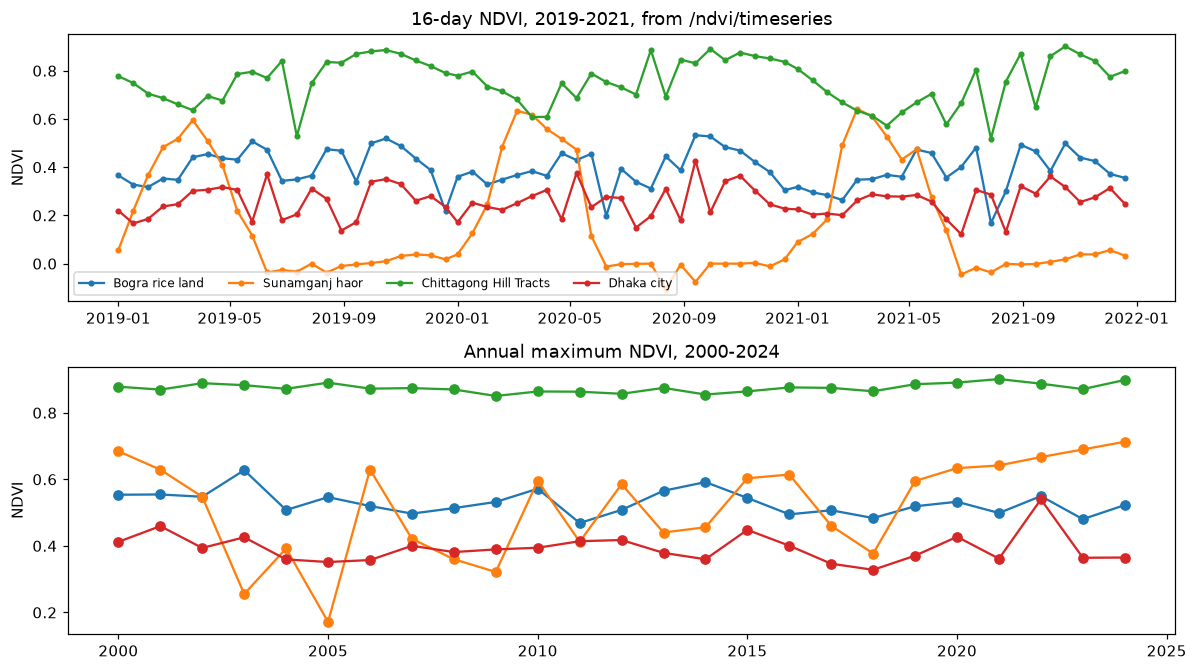

422 start must not be after end | bytes for the full Bogra series: 11428


In [10]:
# /ndvi/timeseries endpoint; plot 16-day series and annual maxima for selected places
class TimeSeries(BaseModel):
    lon: float
    lat: float
    n: int
    dates: list[date]
    ndvi: list[Optional[float]]

@app.get("/ndvi/timeseries", response_model=TimeSeries, tags=["ndvi"])
def ndvi_timeseries(lon: float = Lon, lat: float = Lat, start: Optional[date] = None, end: Optional[date] = None):
    "MODIS 16-day NDVI at a point (1 km pixels), 2000-2024."
    if start and end and start > end:
        raise HTTPException(422, "start must not be after end")
    series = ndvi_at(lon, lat)
    if series is None:
        raise HTTPException(404, "No NDVI at this point (outside the MODIS grid of Bangladesh)")
    keep = np.ones(len(store.dates), bool)
    if start:
        keep &= store.dates >= pd.Timestamp(start)
    if end:
        keep &= store.dates <= pd.Timestamp(end)
    return TimeSeries(lon=lon, lat=lat, n=int(keep.sum()), dates=list(store.dates[keep].date),
                      ndvi=[round(v / 1e4, 4) for v in series[keep]])

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
for name in ["Bogra rice land", "Sunamganj haor", "Chittagong Hill Tracts", "Dhaka city"]:
    lon, lat = places[name]
    ts = client.get("/ndvi/timeseries", params={"lon": lon, "lat": lat, "start": "2019-01-01", "end": "2021-12-31"}).json()
    axes[0].plot(pd.to_datetime(ts["dates"]), ts["ndvi"], marker=".", label=name)
    full = client.get("/ndvi/timeseries", params={"lon": lon, "lat": lat}).json()
    yearly = pd.Series(full["ndvi"], index=pd.to_datetime(full["dates"])).groupby(lambda d: d.year).max()
    axes[1].plot(yearly.index, yearly.values, marker="o", label=name)
axes[0].set_title("16-day NDVI, 2019-2021, from /ndvi/timeseries"); axes[0].set_ylabel("NDVI"); axes[0].legend(fontsize=8, ncol=4)
axes[1].set_title("Annual maximum NDVI, 2000-2024"); axes[1].set_ylabel("NDVI")
plt.tight_layout(); plt.show()
# Invalid date range should 422; also report payload size for a full series
r = client.get("/ndvi/timeseries", params={"lon": 89.37, "lat": 24.85, "start": "2021-01-01", "end": "2020-01-01"})
print(r.status_code, r.json()["detail"], "| bytes for the full Bogra series:",
      len(client.get("/ndvi/timeseries", params={"lon": 89.37, "lat": 24.85}).content))

The four places have distinct seasonal signatures:

- **Sunamganj haor** is a seasonal wetland. NDVI peaks at about 0.6 in March, when Boro rice is
  green, then drops to around zero from June to November when the basin is flooded.
- **The Chittagong Hill Tracts forest** stays green at 0.6-0.9 all year. Its short dips during
  the monsoon are most likely cloud contamination in the 16-day composites.
- **Bogra** cropland shows several crop cycles a year between about 0.2 and 0.5.
- **The Dhaka city** pixel stays low, at 0.1-0.4.

The annual maxima show the haor varying most from year to year (0.17 in 2005, 0.71 in 2024), as
flood timing and crops change. A full 25-year series for one pixel is 11.4 kB of JSON.

### Zonal statistics for a polygon: a POST with a GeoJSON body

A polygon does not fit in a URL, so `/ndvi/zonal` takes a JSON **body**. Its Pydantic model uses
`geojson_pydantic` geometry types, so FastAPI rejects malformed GeoJSON (unclosed rings, wrong
nesting) before our code runs; our code adds checks of its own: the polygon must be valid and no
larger than 25,000 km². The endpoint requires an API key and is rate-limited.

In [11]:
# POST /ndvi/zonal: polygon NDVI stats (API key + rate limit); sample winter vs monsoon for four districts
# Request/response models for zonal NDVI
Day = date            # alias: a field called `date` would otherwise hide the type inside the model

class ZonalRequest(BaseModel):
    geometry: Union[Polygon, MultiPolygon]
    date: Optional[Day] = Field(None, description="Use the MODIS date nearest to this; default: latest")

class ZonalResult(BaseModel):
    date: Day
    area_km2: float
    pixels: int
    mean: Optional[float]
    std: Optional[float]
    p10: Optional[float]
    p90: Optional[float]

MAX_AREA_KM2 = 25_000

# Rasterize a lon/lat polygon onto the NDVI grid
def polygon_pixels(geom):
    "Boolean mask of NDVI pixels whose centres fall inside a lon/lat geometry."
    g = shapely.ops.transform(store.to_ndvi.transform, geom)
    return geometry_mask([mapping(g)], out_shape=store.ndvi_shape, transform=store.ndvi_transform, invert=True)

# Protected zonal stats endpoint
@app.post("/ndvi/zonal", response_model=ZonalResult, tags=["ndvi"], dependencies=[Depends(require_key), Depends(limiter)])
def ndvi_zonal(req: ZonalRequest):
    "NDVI statistics inside a polygon on one MODIS date."
    geom = shape(req.geometry.model_dump(exclude_none=True))
    if not geom.is_valid:
        raise HTTPException(422, f"Invalid polygon: {shapely.is_valid_reason(geom)}")
    area = shapely.area(shapely.ops.transform(to_utm.transform, geom)) / 1e6
    if area > MAX_AREA_KM2:
        raise HTTPException(422, f"Polygon is {area:,.0f} km²; the limit is {MAX_AREA_KM2:,} km²")
    t = len(store.dates) - 1 if req.date is None else int(np.abs(store.dates - pd.Timestamp(req.date)).argmin())
    inside = polygon_pixels(geom)
    v = store.ndvi[t][inside]
    v = v[v != 0] / 1e4
    stats = (dict(mean=float(v.mean()), std=float(v.std()), p10=float(np.percentile(v, 10)), p90=float(np.percentile(v, 90)))
             if v.size else dict(mean=None, std=None, p10=None, p90=None))
    return ZonalResult(date=store.dates[t].date(), area_km2=round(area, 1), pixels=int(v.size),
                       **{k: (None if s is None else round(s, 3)) for k, s in stats.items()})

# Call the endpoint for four districts on two dates
import shapely.ops
headers = {"X-API-Key": KEY}
rows = []
for name in ["Bogra", "Sunamganj", "Rangamati", "Dhaka"]:
    geometry = client.get(f"/districts/{name}").json()["geometry"]         # chain: a district from the API itself
    for when in ["2020-01-15", "2020-08-15"]:
        r = client.post("/ndvi/zonal", json={"geometry": geometry, "date": when}, headers=headers)
        rows.append({"district": name, "requested": when, **r.json()})
        time.sleep(0.5)                                                      # stay within the rate limit
zonal = pd.DataFrame(rows)
zonal

,district,requested,date,area_km2,pixels,mean,std,p10,p90
0,Bogra,2020-01-15,2020-01-17,2920.6,2914,0.427,0.142,0.284,0.599
1,Bogra,2020-08-15,2020-08-12,2920.6,2914,0.558,0.226,0.173,0.760
2,Sunamganj,2020-01-15,2020-01-17,3693.8,3690,0.350,0.101,0.218,0.466
3,Sunamganj,2020-08-15,2020-08-12,3693.8,3662,0.183,0.229,-0.060,0.538
4,Rangamati,2020-01-15,2020-01-17,5760.0,5775,0.739,0.156,0.574,0.845
5,Rangamati,2020-08-15,2020-08-12,5760.0,5775,0.731,0.168,0.541,0.872
6,Dhaka,2020-01-15,2020-01-17,1477.2,1474,0.463,0.150,0.236,0.616
7,Dhaka,2020-08-15,2020-08-12,1477.2,1474,0.445,0.193,0.227,0.688


In [12]:
# Negative tests for /ndvi/zonal: missing key, bad rings, wrong type, too-large polygon, then a valid square
square = {"type": "Polygon", "coordinates": [[[90.3, 23.7], [90.5, 23.7], [90.5, 23.9], [90.3, 23.9], [90.3, 23.7]]]}
cases = {"no API key": dict(json={"geometry": square}),
         "unclosed ring": dict(json={"geometry": {"type": "Polygon", "coordinates": [[[90.3, 23.7], [90.5, 23.7], [90.5, 23.9]]]}}, headers=headers),
         "a point, not a polygon": dict(json={"geometry": {"type": "Point", "coordinates": [90.4, 23.8]}}, headers=headers),
         "self-intersecting": dict(json={"geometry": {"type": "Polygon", "coordinates": [[[90.3, 23.7], [90.5, 23.9], [90.5, 23.7], [90.3, 23.9], [90.3, 23.7]]]}}, headers=headers),
         "too large (all Bangladesh)": dict(json={"geometry": {"type": "Polygon", "coordinates": [[[88.0, 20.6], [92.7, 20.6], [92.7, 26.7], [88.0, 26.7], [88.0, 20.6]]]}}, headers=headers),
         "valid square in Dhaka": dict(json={"geometry": square, "date": "2024-03-01"}, headers=headers)}
for label, kw in cases.items():
    time.sleep(0.5)
    r = client.post("/ndvi/zonal", **kw)
    d = r.json()
    detail = d.get("detail", d)
    if isinstance(detail, list):
        detail = "; ".join(f"{'.'.join(map(str, e['loc'][1:4]))}: {e['msg']}" for e in detail[:2])
    print(f"{r.status_code}  {label:28s} {str(detail)[:150]}")

401  no API key                   Missing or invalid API key


422  unclosed ring                geometry.Polygon.coordinates: List should have at least 4 items after validation, not 3; geometry.MultiPolygon.type: Input should be 'MultiPolygon'


422  a point, not a polygon       geometry.Polygon.type: Input should be 'Polygon'; geometry.Polygon.coordinates: Input should be a valid list


422  self-intersecting            Invalid polygon: Self-intersection[90.4 23.8]


422  too large (all Bangladesh)   Polygon is 324,076 km²; the limit is 25,000 km²


200  valid square in Dhaka        {'date': '2024-03-05', 'area_km2': 451.9, 'pixels': 462, 'mean': 0.377, 'std': 0.136, 'p10': 0.22, 'p90': 0.568}


Chaining the API's own endpoints, district polygon in and statistics out, shows how much the
seasons differ between districts. Sunamganj's mean NDVI falls from 0.35 in January to 0.18 in
August (10th percentile −0.06: open water across the haors). Bogra rises from 0.43 to 0.56 as
monsoon rice grows. Rangamati's forest barely changes (0.74 and 0.73), and Dhaka stays around
0.45. The pixel counts match the district areas (Rangamati: 5,775 pixels of about 1 km² for
5,760 km²).

The error cases show who catches what:

- **Missing key:** the dependency answers 401 before any parsing.
- **Malformed GeoJSON** (an unclosed ring, a point instead of a polygon): rejected by
  `geojson_pydantic` with the exact field.
- **Self-intersecting polygon:** structurally valid GeoJSON, so our own validity check reports where
  the ring crosses itself.
- **A box around all of Bangladesh** (324,076 km²): refused by the size limit, which protects the
  server from requests that are too expensive.

## Long-running work: background jobs

Some requests take longer than a client should wait on an open connection. The standard pattern:
the client submits a **job**, gets `202 Accepted` with a job URL at once, polls the job, and fetches
the result when it is ready. Here the job maps the NDVI trend of a district: for each pixel, the
annual maximum NDVI per year, its **Theil-Sen slope** (the median of all pairwise slopes, robust to
outliers) per decade, and a **Mann-Kendall** test of whether the trend is significant. The result
is a GeoTIFF.

For this part the app runs as a real HTTP server in the background (`geolattice.web.start_server`
works with any ASGI app), because a test client would wait for background work before returning.

In [13]:
# Background NDVI trend jobs: Theil-Sen + Mann-Kendall, poll status, download GeoTIFF results
JOBS: dict = {}

# Job request schema (needs at least 10 years)
class TrendRequest(BaseModel):
    district: str
    start_year: int = Field(2001, ge=2001, le=2024)
    end_year: int = Field(2024, ge=2001, le=2024)

    @model_validator(mode="after")
    def at_least_ten_years(self):
        if self.end_year - self.start_year < 9:
            raise ValueError("a trend needs at least 10 years (end_year - start_year >= 9)")
        return self

# Worker: annual-max Theil-Sen slope + Mann-Kendall p, write GeoTIFF
def run_trend(job_id: str, geom, req: TrendRequest):
    job = JOBS[job_id]
    job.update(status="running", started=datetime.now(timezone.utc).isoformat(timespec="seconds"))
    try:
        t0 = time.perf_counter()
        inside = polygon_pixels(geom)
        rows, cols = np.nonzero(inside)
        r0, r1, c0, c1 = rows.min(), rows.max() + 1, cols.min(), cols.max() + 1
        years = np.arange(req.start_year, req.end_year + 1)
        cube = store.ndvi[:, r0:r1, c0:c1].astype("float32") / 1e4
        cube[cube == 0] = np.nan
        annual = np.stack([np.nanmax(cube[store.dates.year == y], axis=0) for y in years])   # (years, rows, cols)
        n = len(years)
        i, j = np.triu_indices(n, 1)
        diffs = annual[j] - annual[i]
        slopes = diffs / (years[j] - years[i])[:, None, None]
        sen = np.nanmedian(slopes, axis=0) * 10                                             # NDVI per decade
        s = np.nansum(np.sign(diffs), axis=0)
        z = (s - np.sign(s)) / np.sqrt(n * (n - 1) * (2 * n + 5) / 18)
        p = 2 * norm.sf(np.abs(z))
        mask = inside[r0:r1, c0:c1] & np.isfinite(sen)
        sen[~mask], p[~mask] = np.nan, np.nan
        path = OUT / f"trend_{job_id}.tif"
        profile = dict(driver="GTiff", width=c1 - c0, height=r1 - r0, count=2, dtype="float32", crs=store.ndvi_crs, nodata=np.nan,
                       transform=store.ndvi_transform * rasterio.Affine.translation(c0, r0), compress="deflate")
        with rasterio.open(path, "w", **profile) as dst:
            dst.write(np.stack([sen, p]).astype("float32"))
            dst.set_band_description(1, "Theil-Sen slope of annual max NDVI per decade")
            dst.set_band_description(2, "Mann-Kendall p-value")
        valid = sen[mask]
        job.update(status="done", seconds=round(time.perf_counter() - t0, 2), result=f"/jobs/{job_id}/result",
                   summary={"pixels": int(mask.sum()), "median_slope_per_decade": round(float(np.median(valid)), 4),
                            "share_significant_decline": round(float(((valid < 0) & (p[mask] < 0.05)).mean()), 3),
                            "share_significant_increase": round(float(((valid > 0) & (p[mask] < 0.05)).mean()), 3)})
    except Exception as exc:                        # a failed job must say why
        job.update(status="failed", error=f"{type(exc).__name__}: {exc}")

# Submit / poll / download endpoints
@app.post("/jobs/ndvi-trend", status_code=202, tags=["jobs"], dependencies=[Depends(require_key), Depends(limiter)])
def submit_trend(req: TrendRequest, background: BackgroundTasks):
    "Start an NDVI trend analysis for a district; poll the returned URL."
    row = store.districts.iloc[find_district(req.district)]
    job_id = uuid.uuid4().hex[:12]
    JOBS[job_id] = {"id": job_id, "status": "queued", "request": req.model_dump(),
                    "submitted": datetime.now(timezone.utc).isoformat(timespec="seconds")}
    background.add_task(run_trend, job_id, row.geometry, req)
    return JSONResponse({"id": job_id, "status": "queued", "href": f"/jobs/{job_id}"}, status_code=202,
                        headers={"Location": f"/jobs/{job_id}"})

@app.get("/jobs/{job_id}", tags=["jobs"])
def job_status(job_id: str):
    if job_id not in JOBS:
        raise HTTPException(404, f"No job {job_id}")
    return JOBS[job_id]

@app.get("/jobs/{job_id}/result", tags=["jobs"])
def job_result(job_id: str):
    job = job_status(job_id)
    if job["status"] != "done":
        raise HTTPException(409, f"Job is {job['status']}")
    return FileResponse(OUT / f"trend_{job_id}.tif", media_type="image/tiff", filename=f"ndvi_trend_{job['request']['district']}.tif")

# Real HTTP server so BackgroundTasks run; submit jobs and poll until done
server = web.start_server(app)
api = httpx.Client(base_url=server.url, headers=headers, timeout=120)
print(server)
results = {}
for district in ["Dhaka", "Gazipur", "Rangamati", "Bogra"]:
    r = api.post("/jobs/ndvi-trend", json={"district": district})
    job = r.json()
    print(r.status_code, "Location:", r.headers["location"], "|", job["status"])
    polled = []
    while job["status"] in ("queued", "running"):
        time.sleep(0.2)
        job = api.get(f"/jobs/{job['id']}").json()
        polled.append(job["status"])
    print(f"   polled {len(polled)} times -> {job['status']} in {job.get('seconds')} s: {job.get('summary')}")
    tif = api.get(job["result"])
    path = OUT / f"downloaded_trend_{district}.tif"
    path.write_bytes(tif.content)
    results[district] = (path, job)
    time.sleep(0.6)
bad = api.post("/jobs/ndvi-trend", json={"district": "Dhaka", "start_year": 2016})
print(bad.status_code, bad.json()["detail"][0]["msg"])

BackgroundServer(http://127.0.0.1:34551)
202 Location: /jobs/b8f32d432288 | queued


   polled 1 times -> done in 0.04 s: {'pixels': 1474, 'median_slope_per_decade': 0.0125, 'share_significant_decline': 0.229, 'share_significant_increase': 0.407}


202 Location: /jobs/89279541b5fb | queued


   polled 1 times -> done in 0.05 s: {'pixels': 1817, 'median_slope_per_decade': 0.0235, 'share_significant_decline': 0.105, 'share_significant_increase': 0.652}


202 Location: /jobs/7d664f2bb95e | queued


   polled 1 times -> done in 0.2 s: {'pixels': 5775, 'median_slope_per_decade': 0.0063, 'share_significant_decline': 0.026, 'share_significant_increase': 0.34}


202 Location: /jobs/e17784a2ee2e | queued


   polled 1 times -> done in 0.08 s: {'pixels': 2914, 'median_slope_per_decade': 0.0329, 'share_significant_decline': 0.017, 'share_significant_increase': 0.841}


422 Value error, a trend needs at least 10 years (end_year - start_year >= 9)


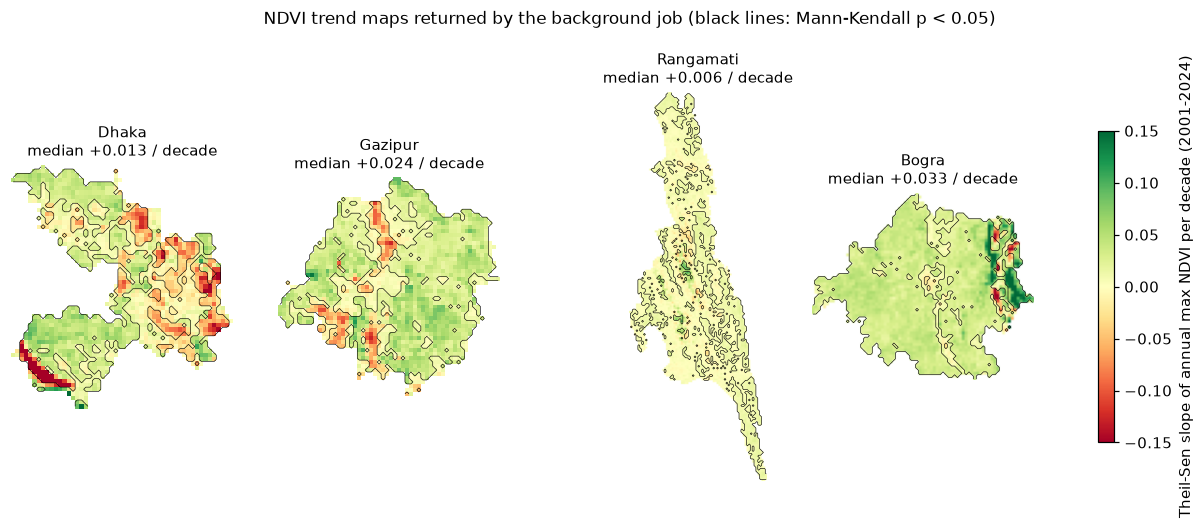

In [14]:
# Map Theil-Sen slopes for each district job; black contours mark Mann-Kendall p < 0.05
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, (district, (path, job)) in zip(axes, results.items()):
    with rasterio.open(path) as src:
        sen, p = src.read(1), src.read(2)
    im = ax.imshow(sen, cmap="RdYlGn", vmin=-0.15, vmax=0.15)
    ax.contour((np.where(np.isfinite(p), p, 1) < 0.05).astype(float), levels=[0.5], colors="k", linewidths=0.4)
    ax.set_title(f"{district}\nmedian {job['summary']['median_slope_per_decade']:+.3f} / decade", fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.8, label="Theil-Sen slope of annual max NDVI per decade (2001-2024)")
fig.suptitle("NDVI trend maps returned by the background job (black lines: Mann-Kendall p < 0.05)", fontsize=11, y=1.04)
plt.show()

Each job was accepted with **202** and a `Location` header, then polled until done. These jobs
finish in 0.04-0.2 s, so the poll catches them almost at once; the pattern is for work that takes
minutes. Invalid job parameters are still rejected immediately (422, "a trend needs at least 10
years"), before any job is created.

The maps show where vegetation changed from 2001 to 2024:

- **Dhaka** has the most significant decline: 22.9% of its pixels, concentrated in the urban core
  and along the southern edge, consistent with the city's growth.
- **Gazipur**, Dhaka's industrial neighbour, has its declines in the west and centre (10.5% of
  pixels).
- **Bogra** is greening almost everywhere (84.1% significant increases, median +0.033 per decade),
  except along its eastern edge, where the Jamuna river's moving channels and sandbars give strong
  gains and losses side by side.
- **Rangamati's** forests change little (median +0.006 per decade).

## Production concerns: keys, limits, compression, OGC and a web map

### API keys and rate limits

`require_key` reads the `X-API-Key` header; without a valid key the answer is **401**. The rate
limiter is a token bucket per key: it allows bursts of 5 requests and refills 2 per second; beyond
that it answers **429 Too Many Requests** with a `Retry-After` header. Both are FastAPI
**dependencies**, attached to endpoints with `dependencies=[Depends(...)]`, so the endpoint code
stays free of security logic.

In [15]:
# Demonstrate the rate limiter: burst until 429, wait, then succeed; also try without an API key
time.sleep(3)                                                   # let the bucket refill
codes = []
for i in range(12):
    r = api.post("/ndvi/zonal", json={"geometry": square})
    codes.append(r.status_code)
retry = r.headers.get("retry-after")
time.sleep(2.5)
after = api.post("/ndvi/zonal", json={"geometry": square}).status_code
print("12 requests in a burst:", codes)
print(f"last 429 said Retry-After: {retry} s; after waiting 2.5 s: {after}")
print("without a key:", httpx.post(server.url + "/ndvi/zonal", json={"geometry": square}).status_code)

12 requests in a burst: [200, 200, 200, 200, 200, 429, 429, 429, 429, 429, 429, 429]
last 429 said Retry-After: 1 s; after waiting 2.5 s: 200
without a key: 401


The bucket allowed the first 5 requests of the burst and answered the other 7 with **429** and
`Retry-After: 1`. After 2.5 s it had refilled and accepted the request again. A request without a
key got **401** before reaching the limiter.

### Compression and CORS

GeoJSON is verbose text, so it compresses well. The GZip middleware compresses responses over
1,000 bytes when the client sends `Accept-Encoding: gzip`, as browsers always do.

In [16]:
# Compare gzip vs uncompressed response sizes; check CORS pre-flight for /ndvi/zonal
rows = []
for path in ["/districts/Rangamati", "/districts", "/ndvi/timeseries?lon=89.37&lat=24.85", "/arsenic/nearest?lon=89.2&lat=22.75&k=50"]:
    plain = httpx.get(server.url + path, headers={"Accept-Encoding": "identity"})
    gz = httpx.get(server.url + path, headers={"Accept-Encoding": "gzip"})
    rows.append({"endpoint": path, "uncompressed kB": round(plain.num_bytes_downloaded / 1e3, 1),
                 "gzip kB": round(gz.num_bytes_downloaded / 1e3, 1), "ratio": round(plain.num_bytes_downloaded / gz.num_bytes_downloaded, 1),
                 "content-encoding": gz.headers.get("content-encoding")})
display(pd.DataFrame(rows))
pre = httpx.options(server.url + "/ndvi/zonal", headers={"Origin": "https://example.org", "Access-Control-Request-Method": "POST",
                                                        "Access-Control-Request-Headers": "X-API-Key"})
print("CORS pre-flight:", pre.status_code, {k: v for k, v in pre.headers.items() if k.startswith("access-control")})

,endpoint,uncompressed kB,gzip kB,ratio,content-encoding
0,/districts/Rangamati,14.8,5.2,2.9,gzip
1,/districts,7.5,1.6,4.7,gzip
2,/ndvi/timeseries?lon=89.37&lat=24.85,11.4,2.9,3.9,gzip
3,/arsenic/nearest?lon=89.2&lat=22.75&k=50,11.4,1.4,8.2,gzip


CORS pre-flight: 200 {'access-control-allow-origin': '*', 'access-control-allow-methods': 'GET, POST', 'access-control-max-age': '600', 'access-control-allow-headers': 'Accept, Accept-Language, Content-Language, Content-Type, X-API-Key'}


Compression cut responses 2.9-8.2 times: the Rangamati polygon from 14.8 to 5.2 kB, and the nearest
50 arsenic fields (repetitive property names) from 11.4 to 1.4 kB. The CORS pre-flight from another
origin was allowed, with the `X-API-Key` header among the permitted headers, so a web page hosted
elsewhere can call the POST endpoints.

### Mounting an OGC API service and a web map

A FastAPI app can **mount** other ASGI apps under a prefix. Mounting `geolattice.web.create_app` at
`/ogc` gives the same API a standard OGC API: Features service (Notebook 08_05) for GIS clients,
next to the custom endpoints. A static folder mounted at `/map` serves a web page that calls the
API from JavaScript.

In [17]:
# Mount OGC API Features and a Leaflet explorer that calls /locate and /soil/estimate on click
app.mount("/ogc", web.create_app(vectors={"districts": store.districts, "fields": store.fields},
                                 title="Bangladesh Agro-Environment API: OGC API - Features"))
# Write a small Leaflet page that consumes the API
(OUT / "map").mkdir()
(OUT / "map" / "index.html").write_text('''<!DOCTYPE html><html><head><meta charset="utf-8"><title>Bangladesh API explorer</title>
<meta name="viewport" content="width=device-width, initial-scale=1">
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<style>html,body,#map{height:100%;margin:0} .info{font:13px sans-serif;line-height:1.4}</style></head>
<body><div id="map"></div><script>
const map = L.map("map").setView([23.8, 90.3], 7);
L.tileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
            {attribution: "Tiles &copy; Esri"}).addTo(map);
fetch("../ogc/collections/districts/items?limit=100").then(r => r.json()).then(fc =>
  L.geoJSON(fc, {style: f => ({color: "#555", weight: 0.6, fillOpacity: 0.55,
     fillColor: f.properties.poverty_pct == null ? "#ccc" : f.properties.poverty_pct > 40 ? "#bd0026" :
                f.properties.poverty_pct > 30 ? "#fd8d3c" : f.properties.poverty_pct > 20 ? "#fecc5c" : "#ffffb2"})}).addTo(map));
map.on("click", async e => {
  const q = `lon=${e.latlng.lng.toFixed(4)}&lat=${e.latlng.lat.toFixed(4)}`;
  const [loc, soil] = await Promise.all([fetch(`../locate?${q}`), fetch(`../soil/estimate?${q}`)]);
  const html = loc.ok ? (l => s => `<div class="info"><b>${l.union}</b>, ${l.upazila}<br>${l.district}, ${l.division}<br>
     District poverty: ${l.district_poverty_pct ?? "n/a"}%<br>NDVI ${l.ndvi_date}: ${l.ndvi_latest ?? "n/a"}<br>
     Soil pH ${s.ph}, SOM ${s.som_pct}% (nearest sample ${s.nearest_km} km)</div>`)(await loc.json())(await soil.json())
     : `<div class="info">${(await loc.json()).detail}</div>`;
  L.popup().setLatLng(e.latlng).setContent(html).openOn(map);
});
</script></body></html>''')
app.mount("/map", StaticFiles(directory=OUT / "map", html=True), name="map")

# Smoke-test mounts and show the map
for path in ["/ogc/conformance", "/ogc/collections/districts/items?limit=2", "/map/"]:
    r = httpx.get(server.url + path)
    print(r.status_code, r.headers["content-type"].split(";")[0], f"{len(r.content):,} bytes", path)
display(IFrame(server.url + "/map/", width="100%", height=450))

200 application/json 143 bytes /ogc/conformance
200 application/geo+json 26,722 bytes /ogc/collections/districts/items?limit=2
200 text/html 1,794 bytes /map/


Click anywhere in Bangladesh: the page calls `/locate` and `/soil/estimate` and shows the answers in
a popup. Districts are coloured by poverty from the mounted OGC service. The map is served by this
notebook's kernel and stops working when the kernel stops.

### The documentation users see

FastAPI's `/docs` page (Swagger UI) is generated from the code: every endpoint, parameter,
constraint, model and example. Users can call the API from it, including POST endpoints with an
API key. `/redoc` shows the same description in another layout.

In [18]:
# Summarize the OpenAPI paths and embed the interactive /docs UI
spec = httpx.get(server.url + "/openapi.json").json()
rows = []
for path, ops in spec["paths"].items():
    for method, op in ops.items():
        params = [p["name"] + ("*" if p.get("required") else "") for p in op.get("parameters", [])]
        rows.append({"method": method.upper(), "path": path, "tag": (op.get("tags") or [""])[0],
                     "parameters (* required)": ", ".join(params), "body": "yes" if "requestBody" in op else ""})
print(f"OpenAPI {spec['openapi']}: {len(spec['paths'])} paths, {len(spec['components']['schemas'])} schemas")
display(IFrame(server.url + "/docs", width="100%", height=420))
pd.DataFrame(rows)

OpenAPI 3.1.0: 12 paths, 13 schemas


,method,path,tag,parameters (* required),body
0,GET,/,service,,
1,GET,/health,service,,
2,GET,/districts,districts,"division, min_poverty, sort, descending, limit",
3,GET,/districts/{name},districts,name*,
4,GET,/locate,spatial,"lon*, lat*",
5,GET,/arsenic/nearest,spatial,"lon*, lat*, k",
6,GET,/soil/estimate,spatial,"lon*, lat*, k, power",
7,GET,/ndvi/timeseries,ndvi,"lon*, lat*, start, end",
8,POST,/ndvi/zonal,ndvi,x-api-key,yes
9,POST,/jobs/ndvi-trend,jobs,x-api-key,yes


## `async def` or `def`: behaviour under load

FastAPI accepts both. An `async def` endpoint runs on the server's event loop, the single thread
that handles every connection; `def` endpoints run in a thread pool. `async def` is right for code
that *waits* (calls to other web services, async databases). For CPU work, such as an
interpolation, `async def` blocks the event loop and with it every other request. We add two
identical heavy endpoints, estimating soil at 200,000 random points, and measure how long
`/health` takes while eight clients (`curl`, in separate processes) call one or the other.

In [19]:
# Benchmark: heavy sync vs async endpoints and /health latency under concurrent load
def heavy_work():
    pts = np.random.default_rng(0).uniform(store.soil_xy.min(axis=0), store.soil_xy.max(axis=0), (200_000, 2))
    est, _ = estimate_soil(pts[:, 0], pts[:, 1], k=12)
    return {"points": len(pts), "mean_ph": round(float(est[:, 0].mean()), 3)}

@app.get("/bench/def", tags=["bench"])
def bench_def():
    return heavy_work()

@app.get("/bench/async", tags=["bench"])
async def bench_async():
    return heavy_work()

t0 = time.perf_counter(); heavy_work(); one = time.perf_counter() - t0
print(f"one heavy request alone: {one:.2f} s")

def health_under_load(path, clients=8):
    # Fire concurrent heavy requests with curl while polling /health
    procs = [subprocess.Popen(["curl", "-s", "-o", "/dev/null", "-w", "%{time_total}", server.url + path],
                              stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True) for _ in range(clients)]
    lat = []
    with httpx.Client() as c:
        while any(p.poll() is None for p in procs):
            t0 = time.perf_counter(); c.get(server.url + "/health"); lat.append((time.perf_counter() - t0) * 1000)
            time.sleep(0.02)
    heavy = [float(p.communicate()[0]) for p in procs]
    lat = np.array(lat)
    return {"health checks": len(lat), "health median ms": np.median(lat), "health max ms": lat.max(),
            "heavy requests: slowest s": max(heavy), "heavy requests: mean s": np.mean(heavy)}

quiet = []
with httpx.Client() as c:
    for _ in range(30):
        t0 = time.perf_counter(); c.get(server.url + "/health"); quiet.append((time.perf_counter() - t0) * 1000)
        time.sleep(0.02)
bench = pd.DataFrame({"no load": {"health checks": len(quiet), "health median ms": np.median(quiet), "health max ms": max(quiet)},
                      "8 × def endpoint": health_under_load("/bench/def"),
                      "8 × async def endpoint": health_under_load("/bench/async")}).T.round(2)
bench

one heavy request alone: 0.49 s


,health checks,health median ms,health max ms,heavy requests: slowest s,heavy requests: mean s
no load,30.0,4.92,7.08,NaN,NaN
8 × def endpoint,26.0,2.07,17.79,0.58,0.55
8 × async def endpoint,1.0,3941.67,3941.67,3.94,2.22


One heavy request takes about 0.5 s. With eight running at once:

- **`def` endpoint:** the eight heavy requests ran in the thread pool and finished within 0.58 s
  (k-d tree queries and NumPy release the GIL for much of the work). `/health` kept answering, 26
  times, in at most 18 ms.
- **`async def` endpoint:** the same code ran on the event loop, one request after another. The
  slowest heavy request took 3.94 s, eight times the work of one, and `/health` got a single answer,
  after 3.9 s. For that whole time the server could not answer anyone.

For CPU work, write `def`, or hand the work to a background job or a worker pool.

## Testing the API

An API is a contract; automated tests check that it keeps it. FastAPI's `TestClient` makes tests
ordinary Python functions, run by `pytest` in a project (`tests/test_api.py`). Here they run
directly. Each test checks one promise of the API.

In [20]:
# Automated checks of key endpoints (locate, districts, soil, NDVI, zonal auth, OpenAPI)
tc = TestClient(app)
tc.__enter__()

def test_health():
    assert tc.get("/health").json()["status"] == "ok"

def test_locate_known_point():
    r = tc.get("/locate", params={"lon": 90.41, "lat": 23.78})
    assert r.status_code == 200 and r.json()["district"] == "Dhaka" and r.json()["division"] == "Dhaka"

def test_locate_rejects_points_outside_the_box():
    assert tc.get("/locate", params={"lon": 100, "lat": 23}).status_code == 422

def test_locate_sea_is_not_found():
    assert tc.get("/locate", params={"lon": 90.5, "lat": 21.0}).status_code == 404

def test_district_lookup_is_case_insensitive_and_suggests():
    assert tc.get("/districts/RANGPUR").status_code == 200
    r = tc.get("/districts/Rangpor")
    assert r.status_code == 404 and "Rangpur" in r.json()["detail"]["suggestions"]

def test_districts_filters_and_sorting():
    rows = tc.get("/districts", params={"division": "Sylhet", "sort": "poverty_pct"}).json()
    assert len(rows) == 4 and [r["poverty_pct"] for r in rows] == sorted(r["poverty_pct"] for r in rows)

def test_soil_estimate_is_within_sample_range():
    s = tc.get("/soil/estimate", params={"lon": 89.37, "lat": 24.85}).json()
    assert store.soil[:, 0].min() <= s["ph"] <= store.soil[:, 0].max() and s["neighbours"] == 12

def test_timeseries_respects_dates():
    ts = tc.get("/ndvi/timeseries", params={"lon": 89.37, "lat": 24.85, "start": "2020-01-01", "end": "2020-12-31"}).json()
    assert ts["n"] == 23 and all(d.startswith("2020") for d in ts["dates"])

def test_zonal_requires_key_and_valid_geometry():
    assert tc.post("/ndvi/zonal", json={"geometry": square}).status_code == 401
    time.sleep(0.6)
    bad = {"type": "Polygon", "coordinates": [[[90.3, 23.7], [90.5, 23.7], [90.5, 23.9]]]}
    assert tc.post("/ndvi/zonal", json={"geometry": bad}, headers=headers).status_code == 422

def test_zonal_matches_direct_computation():
    time.sleep(0.6)
    r = tc.post("/ndvi/zonal", json={"geometry": square, "date": "2020-08-15"}, headers=headers).json()
    t = int(np.abs(store.dates - pd.Timestamp("2020-08-15")).argmin())
    v = store.ndvi[t][polygon_pixels(shape(square))]
    assert r["pixels"] == int((v != 0).sum()) and abs(r["mean"] - v[v != 0].mean() / 1e4) < 1e-3

def test_openapi_lists_every_endpoint():
    paths = tc.get("/openapi.json").json()["paths"]
    assert {"/locate", "/soil/estimate", "/ndvi/zonal", "/jobs/ndvi-trend", "/jobs/{job_id}"} <= set(paths)

# Run every test_* function and collect pass/fail
tests = [f for name, f in list(globals().items()) if name.startswith("test_") and callable(f)]
outcome = []
for f in tests:
    try:
        f(); outcome.append((f.__name__, "PASS", ""))
    except Exception as exc:
        outcome.append((f.__name__, "FAIL", f"{type(exc).__name__}: {exc}"))
pd.DataFrame(outcome, columns=["test", "result", "error"])

,test,result,error
0,test_health,PASS,
1,test_locate_known_point,PASS,
2,test_locate_rejects_points_outside_the_box,PASS,
3,test_locate_sea_is_not_found,PASS,
4,test_district_lookup_is_case_insensitive_and_s...,PASS,
5,test_districts_filters_and_sorting,PASS,
6,test_soil_estimate_is_within_sample_range,PASS,
7,test_timeseries_respects_dates,PASS,
8,test_zonal_requires_key_and_valid_geometry,PASS,
9,test_zonal_matches_direct_computation,PASS,


All eleven tests pass. They check the contract rather than the implementation:

- status codes for valid, invalid and out-of-area input;
- case-insensitive lookup with suggestions;
- sorting, and date filtering of the time series;
- authentication, and zonal statistics matching a direct computation on the same pixels;
- every endpoint appearing in the OpenAPI description.

Run on every change (in CI, Notebook 08_10), they catch a broken endpoint before users do.

## From notebook to deployment

In a project, the API is a package rather than notebook cells:

```text
bd_api/
├── app/
│   ├── main.py          # FastAPI(), middleware, routers included, lifespan
│   ├── data.py          # GeoStore: loading and indexes
│   ├── security.py      # require_key, RateLimiter
│   └── routers/         # districts.py, spatial.py, ndvi.py, jobs.py (APIRouter each)
├── tests/test_api.py    # the tests of Section 11
├── pyproject.toml
└── Dockerfile           # Notebook 08_10
```

It runs with `uvicorn app.main:app --host 0.0.0.0 --port 8000 --workers 4` (several processes, as
measured in Notebook 08_05), behind a reverse proxy (nginx, Caddy, a cloud load balancer) that
terminates HTTPS.

| Concern | In this notebook | In production |
|---|---|---|
| Secrets | A key generated in memory | Environment variables or a secret manager; keys per client, revocable |
| Rate limits | In-memory token bucket | Shared store (Redis) across workers, or the API gateway |
| Jobs | Background tasks in the server process, results in a dict | A task queue (Celery, RQ, Arq) with workers, results in object storage, job records in a database |
| Data | In memory per process | A database (PostGIS), COGs and Zarr in object storage |
| Observability | `/health` | Structured logs, metrics (latency percentiles, error rates), tracing |
| Documentation | `/docs` | The same, plus examples and a versioned URL (`/v1/...`) |

In [21]:
# Shut down the HTTP server and TestClients; list files left in the output folder
server.stop()
for c in (client, tc):
    c.__exit__(None, None, None)
print("server stopped; outputs:", sorted(p.name for p in OUT.iterdir()))

server stopped; outputs: ['downloaded_trend_Bogra.tif', 'downloaded_trend_Dhaka.tif', 'downloaded_trend_Gazipur.tif', 'downloaded_trend_Rangamati.tif', 'map', 'trend_7d664f2bb95e.tif', 'trend_89279541b5fb.tif', 'trend_b8f32d432288.tif', 'trend_e17784a2ee2e.tif']


## Summary and exercises

**Key ideas**

- FastAPI turns typed Python functions into documented, validated HTTP endpoints; Pydantic and
  `geojson_pydantic` reject bad input with clear 422 errors before any analysis runs.
- Load data once (lifespan) and index it: R-trees for polygons, k-d trees for points, arrays for rasters.
- Use the right status codes: 404 for "no such thing", 422 for invalid input, 401 and 429 for access
  control, 202 plus a job URL for long work.
- `async def` is for waiting, not computing: CPU work belongs in `def` endpoints, background jobs or
  separate worker processes.
- Mount standard services (OGC API) and web pages next to custom endpoints; test the API as a contract.

**What we built and measured**

- Eleven endpoints over 64 districts, 5,160 unions, 263 arsenic fields, 37,923 soil samples and
  572 MODIS NDVI images, loaded in about 5 s at start-up.
- Soil estimates by IDW: pH MAE 0.43 in leave-one-out validation, against 0.91 without location.
- Zonal statistics and NDVI trend jobs; Dhaka showed significant greenness decline in 22.9% of its
  pixels from 2001 to 2024, Bogra significant increases in 84.1%.
- API keys (401), a token-bucket rate limit (429), gzip (2.9-8.2× smaller) and CORS.
- An `async def` endpoint doing CPU work stalled the whole server for 3.9 s; the same code in a
  `def` endpoint kept `/health` under 18 ms.
- Eleven automated tests, all passing.

**Exercises**

1. Add `/upazilas/{name}` with poverty from Notebook 08_03's `poverty_clean`, returning 409 when a
   name is ambiguous (several upazilas share it) and listing the candidates.
2. Add a `format` query parameter to `/ndvi/timeseries` that returns CSV (`text/csv`) as well as JSON.
3. Return a confidence interval with `/soil/estimate`, from the leave-one-out errors of Section 6
   at similar distances to the nearest sample.
4. Make `/ndvi/zonal` accept several dates at once and return a table; limit the number of dates.
5. Replace the in-memory job store with files (one JSON per job) so jobs survive a restart, and run
   the API with `--workers 2`. What goes wrong with the in-memory version?

**References**

- FastAPI documentation. https://fastapi.tiangolo.com
- Pydantic documentation. https://docs.pydantic.dev
- geojson-pydantic. https://github.com/developmentseed/geojson-pydantic
- Fielding, R. T. (2000). *Architectural Styles and the Design of Network-based Software Architectures* (REST), ch. 5. University of California, Irvine.
- Sen, P. K. (1968). Estimates of the regression coefficient based on Kendall's tau. *JASA*, 63, 1379-1389.
- Didan, K. (2021). MODIS/Terra Vegetation Indices 16-Day L3 Global 250m SIN Grid V061 (MOD13Q1). NASA EOSDIS LP DAAC.